<a href="https://colab.research.google.com/github/rokeya160210/Skin-Cancer-2-papers-comparison/blob/main/03_reviewer_analysis_all_tables.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 — Reviewer analysis: every table, test and figure from the saved probability matrices

**Answers reviewer points #1, #5, #6, #7, #9, #12, #13, #14, #15, #16, #17, #19 and #22.** It also produces the prediction matrices released for #21.

Inputs are the per-stream softmax matrices written by notebook 02 (ensemble arms) and the EViT revision notebooks. Nothing here trains a model. **Derm7pt labels are never used to choose a weight, a threshold or a temperature**: every such choice is fitted on the HAM10000 lesion-disjoint validation split and then applied unchanged to Derm7pt.

| Section | Reviewer | Main outputs (`OUT_DIR/`) |
|---|---|---|
| 1–3 Load, integrity guard, run accounting | #5, #21, #22 | `run_accounting.csv`, `provenance.json` |
| 4 Headline metrics (mean ± SD, per seed) | #10, #22 | `T_headline_mean_sd.csv/.tex`, `T_per_seed.csv/.tex` |
| 5 Bootstrap CIs (unstratified + class-stratified, shared across seeds) | #14 | `T_bootstrap_ci.csv/.tex` |
| 6 Paired tests: exact McNemar (b, c, raw p, Holm), paired-bootstrap ΔAcc and ΔF1 | #12, #13 | `T_paired_tests.csv/.tex`, `T_between_seed_deltas.csv`, `F_paired_forest.png` |
| 7 Fusion weights: a priori vs equal vs source-validation simplex | #9 | `T_fusion_weights.csv/.tex` |
| 8 Per-class metrics with Wilson intervals | #15 | `T_per_class_*.csv/.tex` |
| 9 Melanoma operating points and the 44.44 / 49.21 reconciliation | #1, #16 | `T_mel_operating_points.csv/.tex`, `T_mel_reconciliation.csv`, `F_mel_roc.png` |
| 10 Calibration: ECE (2 binnings), Brier, NLL, classwise ECE, reliability, source-fitted temperature | #17 | `T_calibration.csv/.tex`, `F_reliability.png` |
| 11 Macro-F1 surrogate: exact gap formula check | #6 | `T_surrogate.csv/.tex` |
| 12 Ensemble diversity | (Table IX) | `T_diversity.csv` |
| 13 Error stratification (MEL↔NV, BKL/BCC) using Derm7pt metadata, IDs only | #19 | `T_err_*.csv`, `persistent_errors.csv`, `F_confusion.png` |
| 14 Checkpoint sensitivity (final vs min-val-loss) | #7 | `T_checkpoint_sensitivity.csv/.tex` |

This notebook also runs on the **submitted-manuscript runs** (3 seeds, no validation probabilities): set `MODE = "manuscript"`. Sections that need validation probabilities then print "skipped" instead of failing. That mode is how the reconciliation in #1 is checked against the numbers already in the paper.

In [1]:
# ================================ CONFIG ====================================
# ---- connect Google Drive FIRST (before any folder is created) ------------------------------
import os, time
def _drive_is_mounted():
    try:
        return any(" /content/drive" in l for l in open("/proc/mounts"))
    except Exception:
        return os.path.ismount("/content/drive")
def mount_google_drive():
    try:
        from google.colab import drive
    except ImportError:
        print("Not running in Colab -> Google Drive not mounted (local paths are used).")
        return False
    if not _drive_is_mounted() and os.path.isdir("/content/drive") and os.listdir("/content/drive"):
        # A plain local folder (e.g. created by an earlier run before Drive was connected) would hide
        # Google Drive. It is NOT your Drive: move it aside (nothing is deleted).
        stray = f"/content/drive_local_copy_{int(time.time())}"
        os.rename("/content/drive", stray)
        print(f"Moved a local folder that was blocking Google Drive to {stray}")
    try:
        drive.mount("/content/drive")
    except Exception as e:
        raise RuntimeError("Google Drive could not be connected. Runtime -> Disconnect and delete runtime, run this "
                           "cell alone, choose the account that owns your Drive and tick 'Select all'. "
                           f"(Colab said: {e})")
    if not os.path.isdir("/content/drive/MyDrive"):
        raise RuntimeError("Google Drive is not visible at /content/drive/MyDrive.")
    print("Google Drive connected.")
    return True
IN_COLAB = mount_google_drive()

MODE = "revision"            # "revision" (notebook-02 runs, 5 seeds) | "manuscript" (submitted runs, 3 seeds)

if MODE == "revision":
    SEEDS = [42, 1000, 50000, 2024, 31415]
    ENS_BASE = "/content/drive/MyDrive/skin_ablation_v2"
else:
    SEEDS = [42, 1000, 50000]
    ENS_BASE = "/content/drive/MyDrive/skin_ablation"
RUNS = {"controlled":  {s: f"{ENS_BASE}/runs/controlled/seed{s}/results" for s in SEEDS},
        "h2_original": {s: f"{ENS_BASE}/runs/h2_original/seed{s}/results" for s in SEEDS}}
# EViT outputs: either the revision exports (prob_evit_test.npy) or the original outputs/ folder
# (y_prob.npy + derm7pt_test_mapping.csv). Set a seed to None if unavailable.
EVIT_RUNS = {s: f"/content/drive/MyDrive/evit_runs/seed{s}/outputs" for s in SEEDS}

REPORT_SEED = 42              # pre-designated reporting seed for single-seed tables/figures
COHORT_CSV = "/content/drive/MyDrive/audit/derm7pt_test_cohort_963.csv"   # from notebook 01 (optional, for #19)
EXCLUDE_TEST_FILES = []       # Derm7pt file names confirmed as duplicates in notebook 01 (usually empty)
OUT_DIR = f"{ENS_BASE}/analysis_{MODE}"

B_BOOT = 2000                 # bootstrap resamples
BOOT_SEED = 2026              # fixed RNG seed for every bootstrap in this notebook
N_BINS = 15                   # calibration bins
SIMPLEX_STEP = 0.05           # fusion-weight grid on the HAM validation split
TARGET_SPECIFICITIES = [0.80, 0.85, 0.90, 0.95]

CLASSES = ["MEL", "NV", "BCC", "BKL", "DF", "VASC"]
W_H3 = {"inception": 0.25, "densenet": 0.30, "convnext": 0.45}     # a-priori weights (Eq. 1)
W_H2O = {"inception": 0.45, "densenet": 0.55}                        # H2-original weights
_s = W_H3["inception"] + W_H3["densenet"]
W_H2C = {"inception": W_H3["inception"] / _s, "densenet": W_H3["densenet"] / _s}
W_EQ = {"inception": 1 / 3, "densenet": 1 / 3, "convnext": 1 / 3}
# HAM10000 six-class development-pool counts (Table IV), used for the prior correction (Eq. 12).
# Section 2 re-derives them from the saved split files and asserts equality.
POOL_COUNTS = {"MEL": 1113, "NV": 6705, "BCC": 514, "BKL": 1099, "DF": 115, "VASC": 142}
EXPECTED_TEST_ORDER_FINGERPRINT = "bba3ea9a777c1eb1"
os.makedirs(OUT_DIR, exist_ok=True)
print("MODE:", MODE, "| seeds:", SEEDS, "| OUT_DIR:", OUT_DIR)

Mounted at /content/drive
Google Drive connected.
MODE: revision | seeds: [42, 1000, 50000, 2024, 31415] | OUT_DIR: /content/drive/MyDrive/skin_ablation_v2/analysis_revision


In [2]:
import json, hashlib, itertools, warnings, datetime, platform
import numpy as np, pandas as pd
from scipy.stats import binomtest
from scipy.optimize import minimize_scalar
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score
import matplotlib
import matplotlib.pyplot as plt
C = len(CLASSES)
Z = 1.959963984540054
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.2.3


## 1. Load every run and guard the alignment of the test set

In [3]:
def _first(path, names):
    for n in names:
        p = os.path.join(path, n)
        if os.path.isfile(p):
            return p
    return None

def load_ensemble_run(path, streams):
    out = {"test": {}, "val": {}, "test_bestval": {}, "val_bestval": {}, "files": {}}
    out["y"] = np.load(os.path.join(path, "y_true.npy")).astype(int)
    yv = _first(path, ["y_val.npy"])
    out["y_val"] = np.load(yv).astype(int) if yv else None
    for s in streams:
        for key, names in [("test", [f"prob_{s}_test.npy", f"prob_{s}.npy"]), ("val", [f"prob_{s}_val.npy"]),
                           ("test_bestval", [f"prob_{s}_test_bestval.npy"]), ("val_bestval", [f"prob_{s}_val_bestval.npy"])]:
            p = _first(path, names)
            if p:
                out[key][s] = np.load(p).astype(np.float64); out["files"][f"{key}/{s}"] = p
    missing = [s for s in streams if s not in out["test"]]
    assert not missing, f"{path}: missing test probabilities for {missing}"
    tcsv = _first(path, ["test_derm7pt.csv"])
    out["test_files"] = list(pd.read_csv(tcsv)["path"].map(os.path.basename)) if tcsv else None
    man = _first(path, ["manifest.json"])
    out["manifest"] = json.load(open(man)) if man else {}
    for f in ["train_split.csv", "val_split.csv"]:
        p = _first(path, [f]); out[f] = pd.read_csv(p) if p else None
    return out

EVIT_ORDER = ["bcc", "bkl", "df", "mel", "nv", "vasc"]          # CFG.CLASSES in the EViT notebook
def load_evit_run(path, ref_files):
    if path is None or not os.path.isdir(path):
        return None
    r = {"files": {}}
    if os.path.isfile(os.path.join(path, "prob_evit_test.npy")):           # revision export (ensemble order)
        r["test"] = np.load(os.path.join(path, "prob_evit_test.npy")).astype(np.float64)
        r["y"] = np.load(os.path.join(path, "y_true_ensemble_order.npy")).astype(int)
        for k, f in [("test_last", "prob_evit_test_last.npy"), ("val", "prob_evit_val.npy")]:
            if os.path.isfile(os.path.join(path, f)):
                r[k] = np.load(os.path.join(path, f)).astype(np.float64)
        r["files"]["test"] = os.path.join(path, "prob_evit_test.npy")
    elif os.path.isfile(os.path.join(path, "y_prob.npy")):                 # original outputs/ folder
        P = np.load(os.path.join(path, "y_prob.npy")).astype(np.float64)
        perm = [EVIT_ORDER.index(c.lower()) for c in CLASSES]
        P = P[:, perm]
        mp = pd.read_csv(os.path.join(path, "derm7pt_test_mapping.csv"))
        files = list(mp["path"].map(os.path.basename))
        if ref_files is not None and files != list(ref_files):           # re-align rows by file name
            pos = {f: i for i, f in enumerate(files)}
            P = P[[pos[f] for f in ref_files]]
            mp = mp.set_index(mp["path"].map(os.path.basename)).loc[ref_files].reset_index(drop=True)
        r["test"] = P
        r["y"] = mp["label"].str.upper().map({c: i for i, c in enumerate(CLASSES)}).values.astype(int)
        r["files"]["test"] = os.path.join(path, "y_prob.npy")
    else:
        return None
    return r

ENS = {"controlled": {}, "h2_original": {}}
for arm, streams in [("controlled", ["inception", "densenet", "convnext"]), ("h2_original", ["inception", "densenet"])]:
    for s in SEEDS:
        p = RUNS[arm].get(s)
        if p and os.path.isdir(p):
            try:
                ENS[arm][s] = load_ensemble_run(p, streams)
            except (AssertionError, FileNotFoundError) as e:
                print(f"WARNING: {arm} seed {s} is incomplete ({e}) -- skipped")
        else:
            print(f"WARNING: {arm} seed {s} not found at {p}")

# ---- use only seeds for which BOTH ensemble arms are complete --------------------
_ready = [s for s in SEEDS if s in ENS["controlled"] and s in ENS["h2_original"]]
if not _ready:
    base = os.path.join(ENS_BASE, "runs")
    print("\nWhat is actually in", base, ":")
    if os.path.isdir(base):
        for root, dirs, files in os.walk(base):
            depth = root[len(base):].count(os.sep)
            if depth <= 2:
                print("  " * depth + os.path.basename(root) + "/", f"({len(files)} files)")
    else:
        print("  (folder does not exist)")
    raise RuntimeError("No seed has both the 'controlled' and the 'h2_original' run. Check that ENS_BASE in the "
                       "CONFIG cell points to the folder notebook 02 wrote (its RUN_DIR line), and that notebook 02's "
                       "status table shows True for every run.")
if len(_ready) < len(SEEDS):
    print(f"\n*** NOTE: analysing seeds {_ready} only; missing or incomplete: "
          f"{[s for s in SEEDS if s not in _ready]}. Re-run this notebook when all runs are finished. ***\n")
SEEDS = _ready
for arm in ENS:
    ENS[arm] = {s: r for s, r in ENS[arm].items() if s in SEEDS}
if REPORT_SEED not in SEEDS:
    print(f"REPORT_SEED {REPORT_SEED} not available -> using {SEEDS[0]} for single-seed tables")
    REPORT_SEED = SEEDS[0]
ref = ENS["controlled"][SEEDS[0]]
y_full = ref["y"]; ref_files = ref["test_files"]
EVIT = {s: load_evit_run(EVIT_RUNS.get(s), ref_files) for s in SEEDS}
print("Loaded:", {a: sorted(v) for a, v in ENS.items()}, "| EViT:", sorted(s for s, v in EVIT.items() if v))
if any(EVIT.get(s) is None for s in SEEDS):
    print("NOTE: EViT outputs missing for seeds", [s for s in SEEDS if EVIT.get(s) is None],
          "-> EViT-Dens169 is left out of the tables until all its seeds are available.")

# ---- integrity guard -----------------------------------------------------------
for arm, d in ENS.items():
    for s, r in d.items():
        assert np.array_equal(r["y"], y_full), f"label vector differs: {arm}/{s}"
        if r["test_files"] is not None and ref_files is not None:
            assert r["test_files"] == ref_files, f"test order differs: {arm}/{s}"
        for k, P in r["test"].items():
            assert P.shape == (len(y_full), C), (arm, s, k, P.shape)
for s, r in EVIT.items():
    if r is not None:
        assert np.array_equal(r["y"], y_full), f"EViT seed {s}: labels/order differ from the ensembles"
if ref_files is not None:
    fp = hashlib.sha256("|".join(ref_files).encode()).hexdigest()[:16]
    print("test-order fingerprint:", fp); assert fp == EXPECTED_TEST_ORDER_FINGERPRINT
print(f"All runs share one test set (N = {len(y_full)}), same labels, same order.")

# ---- optional exclusion of confirmed cross-dataset duplicates (notebook 01) ----
KEEP = np.ones(len(y_full), bool)
if EXCLUDE_TEST_FILES:
    assert ref_files is not None
    KEEP = ~np.isin(ref_files, EXCLUDE_TEST_FILES)
    print(f"Excluding {int((~KEEP).sum())} confirmed duplicates -> N = {int(KEEP.sum())}")
y = y_full[KEEP]; N = len(y)
SUPPORT = np.bincount(y, minlength=C)
print("support:", dict(zip(CLASSES, SUPPORT.tolist())))

Loaded: {'controlled': [42, 1000, 2024, 31415, 50000], 'h2_original': [42, 1000, 2024, 31415, 50000]} | EViT: [42, 1000, 2024, 31415, 50000]
test-order fingerprint: bba3ea9a777c1eb1
All runs share one test set (N = 963), same labels, same order.
support: {'MEL': 252, 'NV': 575, 'BCC': 42, 'BKL': 45, 'DF': 20, 'VASC': 29}


## 2. Configurations evaluated, priors, and run accounting (#5)

Each seed has **trained networks** (EViT: 1; H2-original: 2; controlled harness: 3) and **post-hoc evaluations** computed from their saved outputs. The table below counts both, so the text can say exactly how many of each there are.

In [4]:
STREAM_NAMES = {"inception": "InceptionV3 alone", "densenet": "DenseNet121 alone", "convnext": "ConvNeXt-Large alone"}
ORDER = ["EViT-Dens169", "InceptionV3 alone", "DenseNet121 alone", "ConvNeXt-Large alone",
         "H2-original", "H2-controlled", "H3 equal weights", "H3-controlled", "H3 val-selected"]

def fuse(probs, w):
    return sum(w[k] * probs[k] for k in w)

def simplex_grid(step):
    n = int(round(1 / step)); g = []
    for i in range(n + 1):
        for j in range(n + 1 - i):
            g.append((i / n, j / n, (n - i - j) / n))
    return g

def fast_cm(yt, yp):
    return np.bincount(yt * C + yp, minlength=C * C).reshape(C, C)

def macro_f1_from_cm(cm):
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    p = np.divide(tp, tp + fp, out=np.zeros(C), where=(tp + fp) > 0)
    r = np.divide(tp, tp + fn, out=np.zeros(C), where=(tp + fn) > 0)
    f = np.divide(2 * p * r, p + r, out=np.zeros(C), where=(p + r) > 0)
    return f.mean()

def select_weights_on_validation(val_probs, y_val, step=SIMPLEX_STEP):
    """Uses ONLY HAM10000 validation arrays. Objective: validation macro-F1 (declared before running).
    Ties: higher validation accuracy, then smaller distance to equal weights."""
    best = None
    for w in simplex_grid(step):
        P = w[0] * val_probs["inception"] + w[1] * val_probs["densenet"] + w[2] * val_probs["convnext"]
        pred = P.argmax(1); cm = fast_cm(y_val, pred)
        key = (round(macro_f1_from_cm(cm), 10), round(np.trace(cm) / len(y_val), 10),
               -round(float(np.linalg.norm(np.array(w) - 1 / 3)), 10))
        if best is None or key > best[0]:
            best = (key, w)
    (f1, acc, _), w = best
    return {"inception": w[0], "densenet": w[1], "convnext": w[2]}, f1, acc

HAS_VAL = all(len(ENS["controlled"][s]["val"]) == 3 and ENS["controlled"][s]["y_val"] is not None
              for s in ENS["controlled"])
CONF = {}          # CONF[seed][name] = {"test": P (N x C), "val": P or None}
SELECTED_W = {}
for s in SEEDS:
    c = {}
    if EVIT.get(s) is not None:
        c["EViT-Dens169"] = {"test": EVIT[s]["test"][KEEP], "val": None}
    if s in ENS["controlled"]:
        R = ENS["controlled"][s]; T, V = R["test"], (R["val"] if HAS_VAL else {})
        for k in ["inception", "densenet", "convnext"]:
            c[STREAM_NAMES[k]] = {"test": T[k][KEEP], "val": V.get(k)}
        c["H2-controlled"] = {"test": fuse(T, W_H2C)[KEEP], "val": fuse(V, W_H2C) if HAS_VAL else None}
        c["H3 equal weights"] = {"test": fuse(T, W_EQ)[KEEP], "val": fuse(V, W_EQ) if HAS_VAL else None}
        c["H3-controlled"] = {"test": fuse(T, W_H3)[KEEP], "val": fuse(V, W_H3) if HAS_VAL else None}
        if HAS_VAL:
            w, vf1, vacc = select_weights_on_validation(V, R["y_val"])
            SELECTED_W[s] = {**w, "val_macro_f1": vf1, "val_accuracy": vacc}
            c["H3 val-selected"] = {"test": fuse(T, w)[KEEP], "val": fuse(V, w)}
    if s in ENS["h2_original"]:
        c["H2-original"] = {"test": fuse(ENS["h2_original"][s]["test"], W_H2O)[KEEP], "val": None}
    CONF[s] = c
NAMES = [n for n in ORDER if all(n in CONF[s] for s in SEEDS)]
print("Configurations available at every seed:", NAMES)
if not HAS_VAL:
    print("No validation probabilities in these runs -> sections needing them are skipped.")

# ---- priors for Eq. (12): re-derive the pool counts from the split files and check ----
for s, R in ENS["controlled"].items():
    if R["train_split.csv"] is not None and R["val_split.csv"] is not None:
        lab = pd.concat([R["train_split.csv"]["label"], R["val_split.csv"]["label"]]).astype(int)
        derived = dict(zip(CLASSES, np.bincount(lab, minlength=C).tolist()))
        assert derived == POOL_COUNTS, (s, derived)
        print(f"seed {s}: train+val class counts equal the Table IV pool counts.")
        break
PRIOR = np.array([POOL_COUNTS[c] for c in CLASSES], float); PRIOR /= PRIOR.sum()

# ---- run accounting (#5) -----------------------------------------------------------
acc_rows = [{"item": "EViT-Dens169 training runs (1 network each)", "count": sum(v is not None for v in EVIT.values())},
            {"item": "H2-original training runs (2 networks each)", "count": len(ENS["h2_original"])},
            {"item": "Shared-harness training runs (3 networks each)", "count": len(ENS["controlled"])}]
acc_rows.append({"item": "Total training runs", "count": sum(r["count"] for r in acc_rows)})
acc_rows.append({"item": "Total networks trained",
                 "count": acc_rows[0]["count"] + 2 * acc_rows[1]["count"] + 3 * acc_rows[2]["count"]})
HEADLINE = [n for n in ["EViT-Dens169", "H2-original", "H2-controlled", "H3-controlled"] if n in NAMES]
acc_rows.append({"item": f"Headline evaluations: {len(HEADLINE)} configurations ({', '.join(HEADLINE)}) x {len(SEEDS)} seeds",
                 "count": len(HEADLINE) * len(SEEDS)})
acc_rows.append({"item": f"Additional post-hoc evaluations from the shared-harness outputs ({', '.join(n for n in NAMES if n not in HEADLINE)}) x {len(SEEDS)} seeds",
                 "count": (len(NAMES) - len(HEADLINE)) * len(SEEDS)})
acc_rows.append({"item": "Total evaluations on Derm7pt (no training involved in any of them)", "count": len(NAMES) * len(SEEDS)})
acc_rows.append({"item": f"Primary paired tests (4 comparisons x {len(SEEDS)} seeds)", "count": 4 * len(SEEDS)})
RUN_ACC = pd.DataFrame(acc_rows); print(RUN_ACC.to_string(index=False))
RUN_ACC.to_csv(os.path.join(OUT_DIR, "run_accounting.csv"), index=False)
if SELECTED_W:
    print("\nValidation-selected weights:", json.dumps(SELECTED_W, indent=1))

Configurations available at every seed: ['EViT-Dens169', 'InceptionV3 alone', 'DenseNet121 alone', 'ConvNeXt-Large alone', 'H2-original', 'H2-controlled', 'H3 equal weights', 'H3-controlled', 'H3 val-selected']
seed 42: train+val class counts equal the Table IV pool counts.
                                                                                                                                                                     item  count
                                                                                                                              EViT-Dens169 training runs (1 network each)      5
                                                                                                                              H2-original training runs (2 networks each)      5
                                                                                                                           Shared-harness training runs (3 networks each)      5
                 

## 3. Metric definitions (stated once, used everywhere)

* **Accuracy**: image-level. **Macro-P/R/F1**: unweighted means over the 6 classes of the per-class values (Eq. 6). Macro-F1 is the mean of per-class F1, **not** the harmonic mean of macro-P and macro-R.
* **Macro-AUC**: mean of the 6 one-vs-rest ROC AUCs. **κ**: Cohen's kappa. **MCC**: multiclass Matthews correlation (Gorodkin).
* **Brier**: multiclass Brier score, (1/N) Σᵢ Σ_c (p_ic − 1[yᵢ=c])², range [0, 2].
* **NLL**: −(1/N) Σᵢ log p_{i,yᵢ}, probabilities clipped at 1e-12.
* **ECE (equal-width)**: top-label confidence, `N_BINS` = 15 bins [0,1/15), …, [14/15, 1]. Empty bins carry zero weight.
* **ECE (equal-mass)**: 15 bins with equal numbers of images (sorted by confidence). Reported as a binning-sensitivity check.
* **Classwise ECE**: for each class c, the 15-bin equal-width ECE of p_ic against 1[yᵢ=c], averaged over classes (Kull et al., 2019).
* **Wilson 95% interval**: score interval with z = 1.96, for every proportion (sensitivity, specificity, precision).

In [5]:
def wilson(x, n):
    if n == 0: return (np.nan, np.nan)
    p = x / n; d = 1 + Z**2 / n
    c = (p + Z**2 / (2 * n)) / d; h = Z * np.sqrt(p * (1 - p) / n + Z**2 / (4 * n**2)) / d
    return (max(0.0, c - h), min(1.0, c + h))

def per_class_counts(cm):
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; tn = cm.sum() - tp - fp - fn
    return tp, fp, fn, tn

def prf(cm):
    tp, fp, fn, tn = per_class_counts(cm)
    p = np.divide(tp, tp + fp, out=np.zeros(C), where=(tp + fp) > 0)
    r = np.divide(tp, tp + fn, out=np.zeros(C), where=(tp + fn) > 0)
    f = np.divide(2 * p * r, p + r, out=np.zeros(C), where=(p + r) > 0)
    sp = np.divide(tn, tn + fp, out=np.zeros(C), where=(tn + fp) > 0)
    return p, r, f, sp

def kappa_mcc(cm):
    n = cm.sum(); t = cm.sum(1).astype(float); pk = cm.sum(0).astype(float); c = np.trace(cm)
    po = c / n; pe = (t * pk).sum() / n**2
    kappa = (po - pe) / (1 - pe) if pe < 1 else 0.0
    den = np.sqrt((n**2 - (pk**2).sum()) * (n**2 - (t**2).sum()))
    mcc = (c * n - (t * pk).sum()) / den if den > 0 else 0.0
    return kappa, mcc

def bin_index(conf, n_bins=N_BINS):
    return np.clip(np.floor(conf * n_bins).astype(int), 0, n_bins - 1)

def ece_equal_width(conf, correct, n_bins=N_BINS):
    b = bin_index(conf, n_bins)
    s = np.bincount(b, weights=correct - conf, minlength=n_bins)
    return np.abs(s).sum() / len(conf)

def ece_equal_mass(conf, correct, n_bins=N_BINS):
    o = np.argsort(conf, kind="stable")
    return sum(abs((correct[g] - conf[g]).sum()) for g in np.array_split(o, n_bins)) / len(conf)

def classwise_ece(P, yy, n_bins=N_BINS):
    return np.mean([ece_equal_width(P[:, k], (yy == k).astype(float), n_bins) for k in range(C)])

def macro_auc(yy, P):
    aucs = [roc_auc_score((yy == k).astype(int), P[:, k]) for k in range(C) if 0 < (yy == k).sum() < len(yy)]
    return float(np.mean(aucs))

def surrogate_gap(p, r):
    """Exact closed form of F~ - F_bar (see Section 11)."""
    m = (p + r) > 0
    a = ((p[m] - r[m])**2 / (p[m] + r[m])).sum()
    b = (p.sum() - r.sum())**2 / (p.sum() + r.sum())
    return (a - b) / (2 * C)

def metrics(yy, P):
    P = np.asarray(P, float); pred = P.argmax(1); cm = fast_cm(yy, pred)
    p, r, f, sp = prf(cm); kap, mcc = kappa_mcc(cm)
    conf = P.max(1); correct = (pred == yy).astype(float); onehot = np.eye(C)[yy]
    Pb, Rb = p.mean(), r.mean(); Ft = 2 * Pb * Rb / (Pb + Rb) if Pb + Rb > 0 else 0.0
    return {"Accuracy": 100 * correct.mean(), "Macro-P": 100 * Pb, "Macro-R": 100 * Rb, "Macro-F1": 100 * f.mean(),
            "Macro-AUC": 100 * macro_auc(yy, P), "Kappa": kap, "MCC": mcc,
            "Brier": float(((P - onehot)**2).sum(1).mean()),
            "NLL": float(-np.log(np.clip(P[np.arange(len(yy)), yy], 1e-12, 1)).mean()),
            "ECE15": 100 * ece_equal_width(conf, correct), "ECE15-mass": 100 * ece_equal_mass(conf, correct),
            "Classwise-ECE": 100 * classwise_ece(P, yy), "Confidence": 100 * conf.mean(),
            "Conf-Acc gap": 100 * (conf.mean() - correct.mean()),
            "F1-surrogate": 100 * Ft, "Surrogate bias": 100 * (Ft - f.mean()),
            "Surrogate bias (closed form)": 100 * surrogate_gap(p, r)}

# sanity check against scikit-learn on random data
from sklearn.metrics import f1_score, cohen_kappa_score, matthews_corrcoef, precision_score
_rng = np.random.default_rng(0); _y = _rng.integers(0, C, 500); _P = _rng.dirichlet(np.ones(C), 500)
_m = metrics(_y, _P); _pr = _P.argmax(1)
assert abs(_m["Macro-F1"] - 100 * f1_score(_y, _pr, average="macro")) < 1e-9
assert abs(_m["Macro-P"] - 100 * precision_score(_y, _pr, average="macro", zero_division=0)) < 1e-9
assert abs(_m["Kappa"] - cohen_kappa_score(_y, _pr)) < 1e-9 and abs(_m["MCC"] - matthews_corrcoef(_y, _pr)) < 1e-9
assert abs(_m["Surrogate bias"] - _m["Surrogate bias (closed form)"]) < 1e-9
print("metric implementations agree with scikit-learn; closed-form surrogate gap verified.")

metric implementations agree with scikit-learn; closed-form surrogate gap verified.


## 4. Headline metrics: per seed and mean ± SD (#10, #22)

SD uses the n − 1 denominator. It describes run-to-run spread over the declared seeds and is **not** used for any significance claim.

In [6]:
rows = []
for s in SEEDS:
    for n in NAMES:
        rows.append({"Configuration": n, "Seed": s, **metrics(y, CONF[s][n]["test"])})
PER_SEED = pd.DataFrame(rows)
MAIN = ["Accuracy", "Macro-P", "Macro-R", "Macro-F1", "Macro-AUC", "Kappa", "MCC"]
g = PER_SEED.groupby("Configuration", sort=False)
HEAD = pd.DataFrame({m: g[m].mean() for m in MAIN}).loc[NAMES]
HEAD_SD = pd.DataFrame({m: g[m].std(ddof=1) for m in MAIN}).loc[NAMES]
HEAD_MIN = pd.DataFrame({m: g[m].min() for m in MAIN}).loc[NAMES]
HEAD_MAX = pd.DataFrame({m: g[m].max() for m in MAIN}).loc[NAMES]
fmt = lambda m, s, d=2: f"{m:.{d}f} ± {s:.{d}f}"
HEAD_TXT = pd.DataFrame({m: [fmt(HEAD.at[n, m], HEAD_SD.at[n, m], 3 if m in ("Kappa", "MCC") else 2) for n in NAMES]
                         for m in MAIN}, index=NAMES)
print(f"Mean ± SD over seeds {SEEDS}  (N = {N})"); print(HEAD_TXT.to_string())
PER_SEED.round(4).to_csv(os.path.join(OUT_DIR, "T_per_seed.csv"), index=False)
HEAD_TXT.to_csv(os.path.join(OUT_DIR, "T_headline_mean_sd.csv"))
pd.concat({"mean": HEAD, "sd": HEAD_SD, "min": HEAD_MIN, "max": HEAD_MAX}, axis=1).round(4).to_csv(
    os.path.join(OUT_DIR, "T_headline_mean_sd_min_max.csv"))

def to_latex(df, caption, label, index=True, colfmt=None):
    d = df.copy()
    cols = ([d.index.name or ""] if index else []) + [str(c) for c in d.columns]
    colfmt = colfmt or ("l" * (1 if index else 0) + "c" * len(d.columns))
    esc = lambda x: str(x).replace("±", r"$\pm$").replace("%", r"\%").replace("_", r"\_").replace("→", r"$\rightarrow$").replace("&", r"\&")
    L = [r"\begin{table}[t]", r"\centering", r"\caption{" + caption + "}", r"\label{" + label + "}", r"\small",
         r"\begin{tabular}{" + colfmt + "}", r"\toprule", " & ".join(esc(c) for c in cols) + r" \\", r"\midrule"]
    for i, row in d.iterrows():
        cells = ([esc(i)] if index else []) + [esc(v) for v in row.values]
        L.append(" & ".join(cells) + r" \\")
    L += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    return "\n".join(L)

def save_tex(df, name, caption, label, index=True):
    open(os.path.join(OUT_DIR, name), "w").write(to_latex(df, caption, label, index))

save_tex(HEAD_TXT[["Accuracy", "Macro-P", "Macro-R", "Macro-F1", "Macro-AUC"]], "T_headline_mean_sd.tex",
         f"Derm7pt external test set (N = {N}): mean $\\pm$ sample SD over seeds \\{{{', '.join(map(str, SEEDS))}\\}}. All values in \\%.",
         "tab:headline")
ps = PER_SEED[["Configuration", "Seed"] + MAIN[:5]].copy()
ps[MAIN[:5]] = ps[MAIN[:5]].round(2)
save_tex(ps.set_index("Configuration"), "T_per_seed.tex", f"Per-seed results (N = {N}). All values in \\%.", "tab:perseed")

Mean ± SD over seeds [42, 1000, 50000, 2024, 31415]  (N = 963)
                           Accuracy        Macro-P       Macro-R      Macro-F1     Macro-AUC          Kappa            MCC
EViT-Dens169           27.29 ± 4.53   25.40 ± 1.75  28.10 ± 1.91  18.18 ± 2.40  62.47 ± 3.52  0.065 ± 0.040  0.093 ± 0.045
InceptionV3 alone     46.42 ± 10.57   49.73 ± 1.31  41.21 ± 5.05  35.35 ± 5.43  78.52 ± 2.48  0.217 ± 0.069  0.244 ± 0.059
DenseNet121 alone     47.79 ± 13.66  49.95 ± 11.97  38.03 ± 4.61  31.89 ± 4.68  76.77 ± 3.97  0.190 ± 0.067  0.220 ± 0.055
ConvNeXt-Large alone   66.36 ± 2.26   59.07 ± 4.27  49.24 ± 1.15  46.60 ± 2.68  87.79 ± 0.59  0.392 ± 0.013  0.406 ± 0.017
H2-original            69.08 ± 3.02   66.22 ± 3.42  48.95 ± 3.73  51.37 ± 2.31  88.39 ± 0.91  0.419 ± 0.037  0.435 ± 0.042
H2-controlled         50.49 ± 11.53   50.43 ± 9.15  41.18 ± 5.39  34.76 ± 6.32  81.47 ± 1.04  0.225 ± 0.069  0.255 ± 0.061
H3 equal weights       62.78 ± 4.62   60.48 ± 5.98  50.18 ± 6.60  46.76 ± 4.

## 5. Bootstrap confidence intervals (#14)

**Design (state this in the Methods):**
* B = 2,000 resamples of the N test indices, drawn **once** with a fixed RNG seed and **shared across all configurations and all seeds**. Every configuration and every seed is therefore evaluated on the same resampled images in each iteration.
* For a seed-averaged metric, the metric is computed for each seed on the resample and then averaged over seeds. The interval therefore reflects test-set sampling error for the seed-mean model, not training variability, which the seed SD describes.
* Two schemes: **unstratified** (primary; class supports vary across resamples) and **class-stratified** (supports fixed at their observed values; resampling happens within each class).
* **ECE caveat:** ECE is a biased plug-in estimator. Resampling adds noise to every bin, so bootstrap ECE values are systematically larger than the point estimate, and for a well-calibrated model the percentile interval can lie entirely above it. Read the ECE interval as a scale of uncertainty, alongside the Brier and NLL intervals, which do not have this problem.
* **Clustering:** Derm7pt provides one dermoscopic image per case and no patient identifier (checked in notebook 01). Image-level resampling is therefore lesion-level resampling. Patient-level clustering cannot be modelled, and that is stated as a limitation.

In [7]:
rng = np.random.default_rng(BOOT_SEED)
IDX_U = rng.integers(0, N, size=(B_BOOT, N))
cls_idx = [np.flatnonzero(y == k) for k in range(C)]
IDX_S = np.concatenate([rng.choice(ci, size=(B_BOOT, len(ci)), replace=True) for ci in cls_idx], axis=1)

def precompute(P):
    pred = P.argmax(1); conf = P.max(1); correct = (pred == y).astype(float)
    return {"pred": pred, "correct": correct, "conf": conf, "bin": bin_index(conf),
            "brier": ((P - np.eye(C)[y])**2).sum(1), "nll": -np.log(np.clip(P[np.arange(N), y], 1e-12, 1))}

BOOT_METRICS = ["Accuracy", "Macro-F1", "Kappa", "MCC", "Brier", "NLL", "ECE15"]
def boot_series(pc, IDX):
    out = {m: np.empty(len(IDX)) for m in BOOT_METRICS}
    for b, ix in enumerate(IDX):
        yy, pp = y[ix], pc["pred"][ix]; cm = fast_cm(yy, pp)
        out["Accuracy"][b] = 100 * np.trace(cm) / len(ix)
        out["Macro-F1"][b] = 100 * macro_f1_from_cm(cm)
        out["Kappa"][b], out["MCC"][b] = kappa_mcc(cm)
        out["Brier"][b] = pc["brier"][ix].mean(); out["NLL"][b] = pc["nll"][ix].mean()
        out["ECE15"][b] = 100 * np.abs(np.bincount(pc["bin"][ix], weights=pc["correct"][ix] - pc["conf"][ix],
                                                    minlength=N_BINS)).sum() / len(ix)
    return out

BOOT = {"unstratified": {}, "stratified": {}}
for scheme, IDX in [("unstratified", IDX_U), ("stratified", IDX_S)]:
    for n in NAMES:
        for s in SEEDS:
            BOOT[scheme][(n, s)] = boot_series(precompute(CONF[s][n]["test"]), IDX)
rows = []
for n in NAMES:
    row = {"Configuration": n}
    for m in BOOT_METRICS:
        point = np.mean([metrics(y, CONF[s][n]["test"])[m] for s in SEEDS])
        for scheme in ["unstratified", "stratified"]:
            dist = np.mean([BOOT[scheme][(n, s)][m] for s in SEEDS], axis=0)
            lo, hi = np.percentile(dist, [2.5, 97.5])
            d = 3 if m in ("Kappa", "MCC", "Brier", "NLL") else 2
            row[f"{m} [{scheme}]"] = f"{point:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]"
    rows.append(row)
CI = pd.DataFrame(rows).set_index("Configuration")
print(CI[[c for c in CI.columns if "unstratified" in c]].to_string())
CI.to_csv(os.path.join(OUT_DIR, "T_bootstrap_ci.csv"))
save_tex(CI[[f"{m} [unstratified]" for m in ["Accuracy", "Macro-F1", "Kappa", "MCC"]]].rename(columns=lambda c: c.split(" [")[0]),
         "T_bootstrap_ci.tex",
         f"Seed-mean point estimates with 95\\% bootstrap intervals (B = {B_BOOT}, unstratified, indices shared across seeds and configurations; N = {N}).",
         "tab:bootci")

                     Accuracy [unstratified] Macro-F1 [unstratified]  Kappa [unstratified]    MCC [unstratified]  Brier [unstratified]    NLL [unstratified]  ECE15 [unstratified]
Configuration                                                                                                                                                                     
EViT-Dens169            27.29 [25.00, 29.64]    18.18 [15.22, 21.10]  0.065 [0.048, 0.082]  0.093 [0.068, 0.117]  0.960 [0.932, 0.989]  2.042 [1.950, 2.142]  38.77 [36.58, 41.21]
InceptionV3 alone       46.42 [44.40, 48.47]    35.35 [31.29, 38.76]  0.217 [0.193, 0.240]  0.244 [0.219, 0.269]  0.904 [0.867, 0.939]  2.961 [2.793, 3.137]  41.15 [39.27, 43.12]
DenseNet121 alone       47.79 [45.94, 49.78]    31.89 [28.03, 35.11]  0.190 [0.167, 0.214]  0.220 [0.194, 0.246]  0.897 [0.862, 0.931]  3.717 [3.490, 3.941]  40.89 [39.02, 42.77]
ConvNeXt-Large alone    66.36 [63.84, 69.01]    46.60 [41.17, 50.81]  0.392 [0.352, 0.430]  0.406 [0.367,

## 6. Paired tests (#12, #13)

**Primary family**, fixed before analysis: four comparisons × every seed. Holm–Bonferroni is applied over the whole family. For each test we report the exact discordant counts b (first right, second wrong) and c (first wrong, second right), the exact two-sided binomial McNemar p (full precision), the Holm-adjusted p, and the plug-in ΔAcc and ΔMacro-F1 with 95% paired-bootstrap intervals (same shared indices as Section 5).

**What these tests are and are not.** McNemar and the paired bootstrap condition on one set of trained weights. Their unit of replication is the **test image**. They answer: "given these trained networks, is the difference larger than test-set sampling noise?" They say nothing about variability **between training runs**. That is summarised separately (mean ± SD of the per-seed Δ, range, number of seeds with Δ > 0). With 5 seeds we report that spread descriptively and make no seed-level significance claim.

                                 Comparison  Seed   b   c McNemar p (exact)    Holm p  dAcc (pp)      dAcc 95% CI  dMacroF1 (pp)  dMacroF1 95% CI  Survives Holm (0.05)
         (a) third stream, a-priori weights    42  69 194         6.289e-15 1.006e-13      12.98     (9.76, 16.2)           9.62    (4.61, 14.79)                  True
         (a) third stream, a-priori weights  1000  32 291         2.010e-53 3.818e-52      26.90   (23.78, 30.11)          18.99   (13.79, 24.15)                  True
         (a) third stream, a-priori weights 50000  47 127         1.079e-09 1.294e-08       8.31    (5.61, 11.01)          19.02   (13.81, 24.37)                  True
         (a) third stream, a-priori weights  2024  42  80         7.408e-04 6.667e-03       3.95     (1.77, 6.33)          10.29    (4.48, 16.52)                  True
         (a) third stream, a-priori weights 31415  23 257         3.325e-51 5.985e-50      24.30   (21.39, 27.11)          16.44   (10.13, 22.26)               

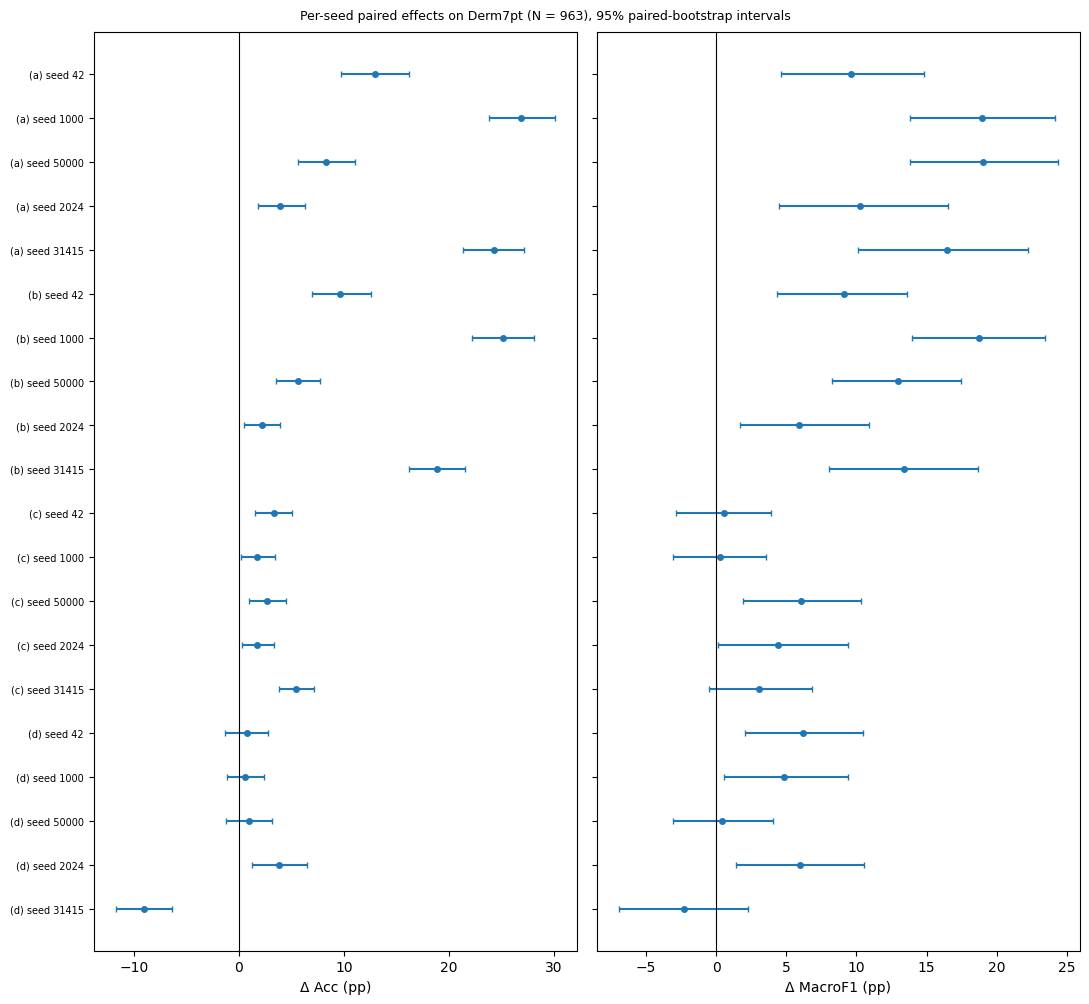

In [8]:
PRIMARY = [("H2-controlled", "H3-controlled", "(a) third stream, a-priori weights"),
           ("H2-controlled", "H3 equal weights", "(b) third stream, equal weights"),
           ("H3 equal weights", "H3-controlled", "(c) weighting only"),
           ("ConvNeXt-Large alone", "H3-controlled", "(d) fusion over best single member")]
SECONDARY = [("H2-original", "H2-controlled", "(e) harness only (different training runs)"),
             ("H3-controlled", "H3 val-selected", "(f) a-priori vs validation-selected weights"),
             ("H3 equal weights", "H3 val-selected", "(g) equal vs validation-selected weights")]

def holm(p):
    p = np.asarray(p, float); m = len(p); o = np.argsort(p); adj = np.empty(m); run = 0.0
    for k, i in enumerate(o):
        run = max(run, min(1.0, (m - k) * p[i])); adj[i] = run
    return adj

def paired_rows(family, fam_name):
    rows = []
    for a, b_, lab in family:
        if a not in NAMES or b_ not in NAMES: continue
        for s in SEEDS:
            pa, pb = CONF[s][a]["test"], CONF[s][b_]["test"]
            ca, cb = pa.argmax(1) == y, pb.argmax(1) == y
            b = int((ca & ~cb).sum()); c = int((~ca & cb).sum())
            p = binomtest(c, b + c, 0.5, alternative="two-sided").pvalue if b + c else 1.0
            ma, mb = metrics(y, pa), metrics(y, pb)
            dA = BOOT["unstratified"][(b_, s)]["Accuracy"] - BOOT["unstratified"][(a, s)]["Accuracy"]
            dF = BOOT["unstratified"][(b_, s)]["Macro-F1"] - BOOT["unstratified"][(a, s)]["Macro-F1"]
            rows.append({"Family": fam_name, "Comparison": lab, "From": a, "To": b_, "Seed": s, "b": b, "c": c,
                         "b+c": b + c, "McNemar p (exact)": p,
                         "dAcc (pp)": mb["Accuracy"] - ma["Accuracy"],
                         "dAcc 95% CI": tuple(np.round(np.percentile(dA, [2.5, 97.5]), 2)),
                         "dMacroF1 (pp)": mb["Macro-F1"] - ma["Macro-F1"],
                         "dMacroF1 95% CI": tuple(np.round(np.percentile(dF, [2.5, 97.5]), 2))})
    df = pd.DataFrame(rows)
    if len(df):
        df["Holm p"] = holm(df["McNemar p (exact)"].values)
        df["Survives Holm (0.05)"] = df["Holm p"] < 0.05
    return df

PT = pd.concat([paired_rows(PRIMARY, f"primary ({len(PRIMARY)} x {len(SEEDS)} = {len(PRIMARY)*len(SEEDS)} tests)"),
                paired_rows(SECONDARY, "secondary")], ignore_index=True)
show = PT.copy(); show["McNemar p (exact)"] = show["McNemar p (exact)"].map(lambda v: f"{v:.3e}")
show["Holm p"] = show["Holm p"].map(lambda v: f"{v:.3e}")
print(show[["Comparison", "Seed", "b", "c", "McNemar p (exact)", "Holm p", "dAcc (pp)", "dAcc 95% CI",
            "dMacroF1 (pp)", "dMacroF1 95% CI", "Survives Holm (0.05)"]].round(2).to_string(index=False))
PT.to_csv(os.path.join(OUT_DIR, "T_paired_tests.csv"), index=False)
tex = show[show["Family"].str.startswith("primary")][["Comparison", "Seed", "b", "c", "McNemar p (exact)", "Holm p",
                                                       "dAcc (pp)", "dMacroF1 (pp)", "dMacroF1 95% CI"]].copy()
tex["dAcc (pp)"] = tex["dAcc (pp)"].map(lambda v: f"{v:+.2f}"); tex["dMacroF1 (pp)"] = tex["dMacroF1 (pp)"].map(lambda v: f"{v:+.2f}")
save_tex(tex.set_index("Comparison"), "T_paired_tests.tex",
         "Paired comparisons on the same test images. b: first configuration right, second wrong; c: the reverse. "
         "Exact two-sided McNemar p and Holm-adjusted p over the primary family; 95\\% paired-bootstrap interval on $\\Delta$macro-F1.",
         "tab:paired")

# between-seed summary (descriptive)
bs = []
for (lab, a, b_), grp in PT.groupby(["Comparison", "From", "To"], sort=False):
    bs.append({"Comparison": lab, "n seeds": len(grp),
               "dAcc mean ± SD": fmt(grp["dAcc (pp)"].mean(), grp["dAcc (pp)"].std(ddof=1)),
               "dAcc range": f"[{grp['dAcc (pp)'].min():+.2f}, {grp['dAcc (pp)'].max():+.2f}]",
               "dMacroF1 mean ± SD": fmt(grp["dMacroF1 (pp)"].mean(), grp["dMacroF1 (pp)"].std(ddof=1)),
               "seeds with dAcc > 0": int((grp["dAcc (pp)"] > 0).sum()),
               "seeds surviving Holm": int(grp["Survives Holm (0.05)"].sum())})
BS = pd.DataFrame(bs); print("\nBetween-seed summary (descriptive only):"); print(BS.to_string(index=False))
BS.to_csv(os.path.join(OUT_DIR, "T_between_seed_deltas.csv"), index=False)

# forest plot of the per-seed paired effects (#12)
prim = PT[PT["Family"].str.startswith("primary")]
fig, axes = plt.subplots(1, 2, figsize=(11, 0.45 * len(prim) + 1.2), sharey=True)
labels = [f"{r.Comparison.split(')')[0]}) seed {r.Seed}" for r in prim.itertuples()]
for ax, col, ci in [(axes[0], "dAcc (pp)", "dAcc 95% CI"), (axes[1], "dMacroF1 (pp)", "dMacroF1 95% CI")]:
    yy = np.arange(len(prim))[::-1]
    lo = [v[0] for v in prim[ci]]; hi = [v[1] for v in prim[ci]]
    ax.errorbar(prim[col], yy, xerr=[prim[col] - lo, np.array(hi) - prim[col]], fmt="o", ms=4, capsize=2)
    ax.axvline(0, c="k", lw=0.8); ax.set_xlabel(col.replace("d", "Δ ")); ax.set_yticks(yy); ax.set_yticklabels(labels, fontsize=7)
fig.suptitle(f"Per-seed paired effects on Derm7pt (N = {N}), 95% paired-bootstrap intervals", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "F_paired_forest.png"), dpi=300); plt.show()

## 7. Fusion weights: a priori vs equal vs source-validation simplex (#9)

The simplex is searched in steps of 0.05 (231 weight vectors) on the **HAM10000 lesion-disjoint validation split only**, maximising validation macro-F1. The objective was declared before the search. The selected vector is then applied unchanged to Derm7pt. The function `select_weights_on_validation` receives only validation arrays, so it cannot see Derm7pt.

In [9]:
if HAS_VAL:
    rows = []
    for s in SEEDS:
        for n, w in [("H3-controlled", W_H3), ("H3 equal weights", W_EQ), ("H3 val-selected", SELECTED_W[s])]:
            m_test = metrics(y, CONF[s][n]["test"]); m_val = metrics(ENS["controlled"][s]["y_val"], CONF[s][n]["val"])
            rows.append({"Seed": s, "Fusion": n, "w_Inc": round(w["inception"], 3), "w_Den": round(w["densenet"], 3),
                         "w_Cnx": round(w["convnext"], 3), "HAM-val macro-F1": m_val["Macro-F1"],
                         "HAM-val Acc": m_val["Accuracy"], "Derm7pt Acc": m_test["Accuracy"],
                         "Derm7pt macro-F1": m_test["Macro-F1"], "Derm7pt macro-AUC": m_test["Macro-AUC"]})
    FW = pd.DataFrame(rows)
    print(FW.round(2).to_string(index=False))
    summ = FW.groupby("Fusion", sort=False)[["HAM-val macro-F1", "Derm7pt Acc", "Derm7pt macro-F1", "Derm7pt macro-AUC"]].agg(["mean", "std"])
    print("\nMean / SD over seeds:"); print(summ.round(2).to_string())
    FW.round(4).to_csv(os.path.join(OUT_DIR, "T_fusion_weights.csv"), index=False)
    save_tex(FW.round(2).set_index("Fusion"), "T_fusion_weights.tex",
             "Fusion weights: a-priori (0.25, 0.30, 0.45), equal (1/3 each), and the simplex point selected on the HAM10000 "
             "lesion-disjoint validation split (step 0.05, objective: validation macro-F1). Derm7pt labels were not used.",
             "tab:fusionweights")
else:
    print("Skipped: these runs have no validation probabilities (use the notebook-02 revision runs).")

 Seed           Fusion  w_Inc  w_Den  w_Cnx  HAM-val macro-F1  HAM-val Acc  Derm7pt Acc  Derm7pt macro-F1  Derm7pt macro-AUC
   42    H3-controlled   0.25   0.30   0.45             70.30        82.73        66.98             53.03              87.62
   42 H3 equal weights   0.33   0.33   0.33             66.10        81.08        63.66             52.49              87.04
   42  H3 val-selected   0.15   0.35   0.50             75.51        83.87        67.60             51.55              87.64
 1000    H3-controlled   0.25   0.30   0.45             67.54        82.15        68.12             50.20              86.57
 1000 H3 equal weights   0.33   0.33   0.33             65.26        80.72        66.36             49.93              86.26
 1000  H3 val-selected   0.35   0.05   0.60             70.93        82.05        68.85             48.23              87.53
50000    H3-controlled   0.25   0.30   0.45             59.42        77.64        66.77             47.02              86.59


## 8. Per-class metrics with Wilson intervals (#15)

For every class: support, TP/FP/FN/TN, sensitivity, specificity and precision with Wilson 95% intervals, F1 with a 95% bootstrap interval, and one-vs-rest AUC. Rows with support < 30 (DF n = 20, VASC n = 29) are flagged. Their intervals are the honest statement of how little they constrain.

In [10]:
def per_class_table(P, seed_label, boot_idx=IDX_U):
    pred = P.argmax(1); cm = fast_cm(y, pred); tp, fp, fn, tn = per_class_counts(cm); p, r, f, sp = prf(cm)
    f1b = np.empty((len(boot_idx), C))
    for b, ix in enumerate(boot_idx):
        f1b[b] = prf(fast_cm(y[ix], pred[ix]))[2]
    rows = []
    for k, cl in enumerate(CLASSES):
        sl, sh = wilson(tp[k], tp[k] + fn[k]); pl, ph = wilson(tp[k], tp[k] + fp[k]); ql, qh = wilson(tn[k], tn[k] + fp[k])
        fl, fh = np.percentile(f1b[:, k], [2.5, 97.5])
        rows.append({"Seed": seed_label, "Class": cl, "Support": int(tp[k] + fn[k]), "TP": int(tp[k]), "FP": int(fp[k]),
                     "FN": int(fn[k]), "TN": int(tn[k]),
                     "Sensitivity": f"{100*r[k]:.2f} [{100*sl:.1f}, {100*sh:.1f}]",
                     "Specificity": f"{100*sp[k]:.2f} [{100*ql:.1f}, {100*qh:.1f}]",
                     "Precision": f"{100*p[k]:.2f} [{100*pl:.1f}, {100*ph:.1f}]" if tp[k] + fp[k] else "n/a (no predictions)",
                     "F1": f"{100*f[k]:.2f} [{100*fl:.1f}, {100*fh:.1f}]",
                     "AUC": f"{100*roc_auc_score((y == k).astype(int), P[:, k]):.2f}",
                     "small support (<30)": bool(tp[k] + fn[k] < 30)})
    return pd.DataFrame(rows)

for n in [x for x in ["H3-controlled", "H2-controlled", "ConvNeXt-Large alone", "H2-original", "EViT-Dens169"] if x in NAMES]:
    tabs = [per_class_table(CONF[s][n]["test"], s) for s in SEEDS]
    allpc = pd.concat(tabs, ignore_index=True)
    slug = n.replace(" ", "_").replace("-", "").replace("(", "").replace(")", "")
    allpc.to_csv(os.path.join(OUT_DIR, f"T_per_class_{slug}_all_seeds.csv"), index=False)
    rep = allpc[allpc["Seed"] == REPORT_SEED].drop(columns=["Seed"]).set_index("Class")
    save_tex(rep.drop(columns=["small support (<30)"]), f"T_per_class_{slug}_seed{REPORT_SEED}.tex",
             f"Per-class metrics, {n}, seed {REPORT_SEED} (the pre-designated reporting seed), Derm7pt N = {N}. "
             "Brackets: Wilson 95\\% intervals (sensitivity, specificity, precision) and 95\\% bootstrap interval (F1).",
             f"tab:perclass_{slug}")
    # mean ± SD of per-class point values over seeds
    num = []
    for s in SEEDS:
        P = CONF[s][n]["test"]; p, r, f, sp = prf(fast_cm(y, P.argmax(1)))
        for k, cl in enumerate(CLASSES):
            num.append({"Seed": s, "Class": cl, "Sens": 100 * r[k], "Spec": 100 * sp[k], "Prec": 100 * p[k], "F1": 100 * f[k]})
    num = pd.DataFrame(num).groupby("Class", sort=False)[["Sens", "Spec", "Prec", "F1"]].agg(["mean", "std"]).loc[CLASSES]
    num.round(2).to_csv(os.path.join(OUT_DIR, f"T_per_class_{slug}_mean_sd.csv"))
    if n == "H3-controlled":
        print(f"{n}, seed {REPORT_SEED}:"); print(rep.to_string())
        print(f"\n{n}, mean (SD) over seeds:"); print(num.round(2).to_string())

H3-controlled, seed 42:
       Support   TP   FP   FN   TN         Sensitivity         Specificity           Precision                  F1    AUC  small support (<30)
Class                                                                                                                                         
MEL        252   90   20  162  691  35.71 [30.1, 41.8]  97.19 [95.7, 98.2]  81.82 [73.6, 87.9]  49.72 [42.9, 55.9]  79.93                False
NV         575  479  123   96  265  83.30 [80.0, 86.1]  68.30 [63.5, 72.7]  79.57 [76.2, 82.6]  81.39 [78.8, 83.8]  84.16                False
BCC         42   14    5   28  916  33.33 [21.0, 48.4]  99.46 [98.7, 99.8]  73.68 [51.2, 88.2]  45.90 [30.0, 60.3]  87.97                False
BKL         45   37  153    8  765  82.22 [68.7, 90.7]  83.33 [80.8, 85.6]  19.47 [14.5, 25.7]  31.49 [23.2, 38.6]  90.26                False
DF          20   15   11    5  932  75.00 [53.1, 88.8]  98.83 [97.9, 99.3]  57.69 [38.9, 74.5]  65.22 [45.7, 80.0]  94

## 9. Melanoma operating points (#1, #16)

**Decision rules.** MEL-vs-rest is scored with s = p_MEL.
1. **arg max** (used for every headline number). MEL is predicted iff p_MEL ≥ max_{c≠MEL} p_c. This is **not** a fixed threshold on p_MEL: the implied cut-off depends on how the remaining mass is spread over the other five classes. It is always > 1/6 and never above 1/2, since p_MEL > 1/2 guarantees a MEL prediction.
2. **Training-prior correction (Eq. 12).** ŷ = arg max_c p_c / π_c, with π the HAM10000 pool frequencies. If the classifier's posterior is p(c|x) ∝ p(x|c) π_c, this is the Bayes rule under equal priors. It uses no Derm7pt information.
3. **Source-validation thresholds (deployable).** For each target specificity s*, the threshold is the s*-quantile of p_MEL among **HAM10000 validation** non-melanomas. It is applied unchanged to Derm7pt, and the *achieved* Derm7pt sensitivity and specificity are reported, both with Wilson intervals.
4. **Test-derived points (descriptive only).** The same quantile computed on Derm7pt non-melanomas. These are points on the Derm7pt ROC curve. They use test labels and are **not achievable operating points**. They may be reported only as a property of the score distribution.

                                        Sensitivity %        Specificity %      
                                                 mean    std          mean   std
Decision rule                                                                   
arg max                                         29.92   4.15         97.16  1.13
prior correction (Eq. 12)                       31.03   8.79         91.95  4.52
HAM-val threshold, spec*=80%                    55.79  10.55         85.12  7.15
HAM-val threshold, spec*=85%                    47.78  10.92         89.54  6.20
HAM-val threshold, spec*=90%                    38.33  11.48         93.87  4.19
HAM-val threshold, spec*=95%                    27.46  10.97         97.44  1.91
[descriptive] Derm7pt-derived, spec=80%         63.17   3.05         80.03  0.00
[descriptive] Derm7pt-derived, spec=85%         57.54   3.86         85.09  0.00
[descriptive] Derm7pt-derived, spec=90%         49.21   2.38         90.01  0.00
[descriptive] Derm7pt-derive

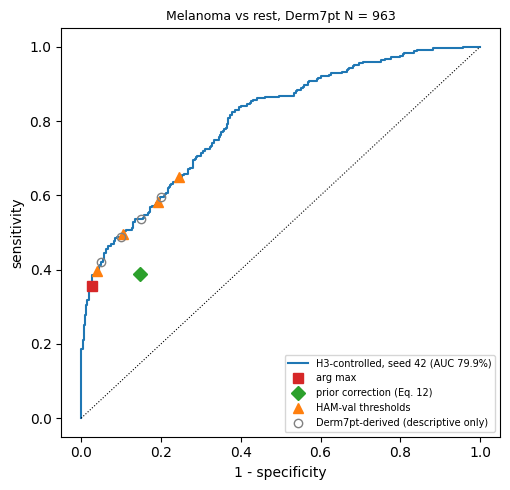

In [11]:
def mel_rates(pred_mel):
    pos = y == 0
    tp = int((pred_mel & pos).sum()); fn = int((~pred_mel & pos).sum()); tn = int((~pred_mel & ~pos).sum()); fp = int((pred_mel & ~pos).sum())
    return tp, fn, tn, fp

def thr_at_spec(neg_scores, s):
    srt = np.sort(neg_scores); k = int(np.ceil(s * len(srt))) - 1
    return srt[min(max(k, 0), len(srt) - 1)]           # predict MEL iff score > threshold -> spec >= s

def fmt_rate(x, n):
    lo, hi = wilson(x, n); return f"{100*x/n:.2f} [{100*lo:.1f}, {100*hi:.1f}]"

def mel_rows(name):
    rows = []
    for s in SEEDS:
        P = CONF[s][name]["test"]; sc = P[:, 0]
        rules = [("arg max", P.argmax(1) == 0),
                 ("prior correction (Eq. 12)", (P / PRIOR).argmax(1) == 0)]
        Pv = CONF[s][name].get("val")
        if Pv is not None:
            yv = ENS["controlled"][s]["y_val"]
            for t in TARGET_SPECIFICITIES:
                rules.append((f"HAM-val threshold, spec*={int(100*t)}%", sc > thr_at_spec(Pv[yv != 0, 0], t)))
        for t in TARGET_SPECIFICITIES:
            rules.append((f"[descriptive] Derm7pt-derived, spec={int(100*t)}%", sc > thr_at_spec(sc[y != 0], t)))
        for rule, pm in rules:
            tp, fn, tn, fp = mel_rates(pm)
            rows.append({"Configuration": name, "Seed": s, "Decision rule": rule, "TP": tp, "FN": fn, "TN": tn, "FP": fp,
                         "Sensitivity %": 100 * tp / (tp + fn), "Specificity %": 100 * tn / (tn + fp),
                         "Sensitivity [Wilson]": fmt_rate(tp, tp + fn), "Specificity [Wilson]": fmt_rate(tn, tn + fp),
                         "MEL-vs-rest AUC %": 100 * roc_auc_score((y == 0).astype(int), sc)})
    return pd.DataFrame(rows)

MEL = pd.concat([mel_rows(n) for n in ["H3-controlled", "H2-controlled", "H3 val-selected"] if n in NAMES], ignore_index=True)
MEL.to_csv(os.path.join(OUT_DIR, "T_mel_operating_points.csv"), index=False)
MS = MEL.groupby(["Configuration", "Decision rule"], sort=False)[["Sensitivity %", "Specificity %"]].agg(["mean", "std"]).round(2)
print(MS.loc["H3-controlled"].to_string())
mt = MEL[MEL["Configuration"] == "H3-controlled"].groupby("Decision rule", sort=False)[["Sensitivity %", "Specificity %"]].agg(["mean", "std"])
mt_txt = pd.DataFrame({"Sensitivity": [fmt(a, b) for a, b in mt["Sensitivity %"].values],
                       "Specificity": [fmt(a, b) for a, b in mt["Specificity %"].values]}, index=mt.index)
save_tex(mt_txt, "T_mel_operating_points.tex",
         f"Melanoma versus rest, H3-controlled, mean $\\pm$ SD over seeds \\{{{', '.join(map(str, SEEDS))}\\}} (N = {N}). "
         "Rows marked [descriptive] use Derm7pt labels to place the threshold and are not achievable operating points; "
         "HAM-val thresholds are fixed on the HAM10000 validation split and applied unchanged.", "tab:mel")

# ---- reconciliation table for reviewer #1 ----------------------------------------
am = MEL[(MEL["Configuration"] == "H3-controlled") & (MEL["Decision rule"] == "arg max")].set_index("Seed")
rec = [{"Where it appears": "Table XIII / Table XII (per-class, single seed)", "Model": "H3-controlled (0.25/0.30/0.45)",
        "Seed(s)": str(REPORT_SEED), "Decision rule": "arg max", "MEL TP / support": f"{am.at[REPORT_SEED,'TP']}/{SUPPORT[0]}",
        "MEL sensitivity %": round(am.at[REPORT_SEED, "Sensitivity %"], 2)},
       {"Where it appears": "Abstract, Table XV, Sec. V-L, VI-C, VII (seed mean)", "Model": "H3-controlled (0.25/0.30/0.45)",
        "Seed(s)": ", ".join(map(str, SEEDS)), "Decision rule": "arg max",
        "MEL TP / support": " / ".join(f"{am.at[s,'TP']}" for s in SEEDS) + f" (of {SUPPORT[0]})",
        "MEL sensitivity %": round(am["Sensitivity %"].mean(), 2)}]
for s in SEEDS:
    rec.append({"Where it appears": "per-seed value (supplementary)", "Model": "H3-controlled (0.25/0.30/0.45)", "Seed(s)": str(s),
                "Decision rule": "arg max", "MEL TP / support": f"{am.at[s,'TP']}/{SUPPORT[0]}",
                "MEL sensitivity %": round(am.at[s, "Sensitivity %"], 2)})
REC = pd.DataFrame(rec); print("\nReconciliation (reviewer #1):"); print(REC.to_string(index=False))
REC.to_csv(os.path.join(OUT_DIR, "T_mel_reconciliation.csv"), index=False)

# ---- figure: MEL ROC with operating points (reporting seed) ----------------------
P = CONF[REPORT_SEED]["H3-controlled"]["test"]; fpr, tpr, _ = roc_curve((y == 0).astype(int), P[:, 0])
fig, ax = plt.subplots(figsize=(5.2, 5)); ax.plot(fpr, tpr, lw=1.5, label=f"H3-controlled, seed {REPORT_SEED} (AUC {100*roc_auc_score((y == 0).astype(int), P[:, 0]):.1f}%)")
sub = MEL[(MEL["Configuration"] == "H3-controlled") & (MEL["Seed"] == REPORT_SEED)]
for _, r in sub.iterrows():
    x, yy = 1 - r["Specificity %"] / 100, r["Sensitivity %"] / 100
    if r["Decision rule"].startswith("[descriptive]"):
        ax.plot(x, yy, "o", mfc="none", mec="grey", ms=6)
    elif r["Decision rule"] == "arg max":
        ax.plot(x, yy, "s", c="C3", ms=7, label="arg max")
    elif r["Decision rule"].startswith("prior"):
        ax.plot(x, yy, "D", c="C2", ms=7, label="prior correction (Eq. 12)")
    else:
        ax.plot(x, yy, "^", c="C1", ms=7, label="HAM-val thresholds" if "HAM-val thresholds" not in ax.get_legend_handles_labels()[1] else None)
ax.plot([], [], "o", mfc="none", mec="grey", label="Derm7pt-derived (descriptive only)")
ax.plot([0, 1], [0, 1], "k:", lw=0.8); ax.set_xlabel("1 - specificity"); ax.set_ylabel("sensitivity")
ax.set_title(f"Melanoma vs rest, Derm7pt N = {N}", fontsize=9); ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"F_mel_roc_seed{REPORT_SEED}.png"), dpi=300); plt.show()

## 10. Calibration (#17)

ECE is reported with two binnings (equal-width, primary; equal-mass, sensitivity), together with the multiclass Brier score, NLL and classwise ECE. All are given as mean ± SD over seeds, with a 95% bootstrap interval on the seed-mean (Section 5 design). Reliability diagrams show all 15 bins. A bin's marker size reflects its count, so sparse bins are visible rather than hidden.

**Source-fitted temperature scaling (supplementary).** If validation probabilities exist, a single temperature T is fitted per configuration and seed by minimising NLL on the **HAM10000 validation split**. It is applied as softmax(log p / T) to Derm7pt. This shows how much of the miscalibration under shift a source-only calibrator can remove.

                              ECE15     ECE15-mass Classwise-ECE          Brier            NLL    Confidence       Accuracy   Conf-Acc gap    ECE15 95% CI    Brier 95% CI      NLL 95% CI
EViT-Dens169           38.77 ± 9.69   38.85 ± 9.51  16.63 ± 2.28  0.960 ± 0.131  2.042 ± 0.467  65.91 ± 6.30   27.29 ± 4.53   38.62 ± 9.82  [36.58, 41.21]  [0.932, 0.989]  [1.950, 2.142]
InceptionV3 alone     41.15 ± 10.14  41.14 ± 10.13  15.18 ± 3.48  0.904 ± 0.183  2.961 ± 0.872  87.55 ± 1.97  46.42 ± 10.57  41.14 ± 10.13  [39.27, 43.12]  [0.867, 0.939]  [2.793, 3.137]
DenseNet121 alone     40.89 ± 11.32  40.81 ± 11.36  15.15 ± 4.38  0.897 ± 0.236  3.717 ± 1.324  88.60 ± 5.80  47.79 ± 13.66  40.81 ± 11.36  [39.02, 42.77]  [0.862, 0.931]  [3.490, 3.941]
ConvNeXt-Large alone   20.72 ± 1.19   20.59 ± 1.17   8.12 ± 0.66  0.539 ± 0.033  1.475 ± 0.074  86.94 ± 1.82   66.36 ± 2.26   20.59 ± 1.17  [18.52, 23.24]  [0.495, 0.582]  [1.317, 1.643]
H2-original            16.06 ± 3.15   16.52 ± 2.65   7.00 ± 0.74 

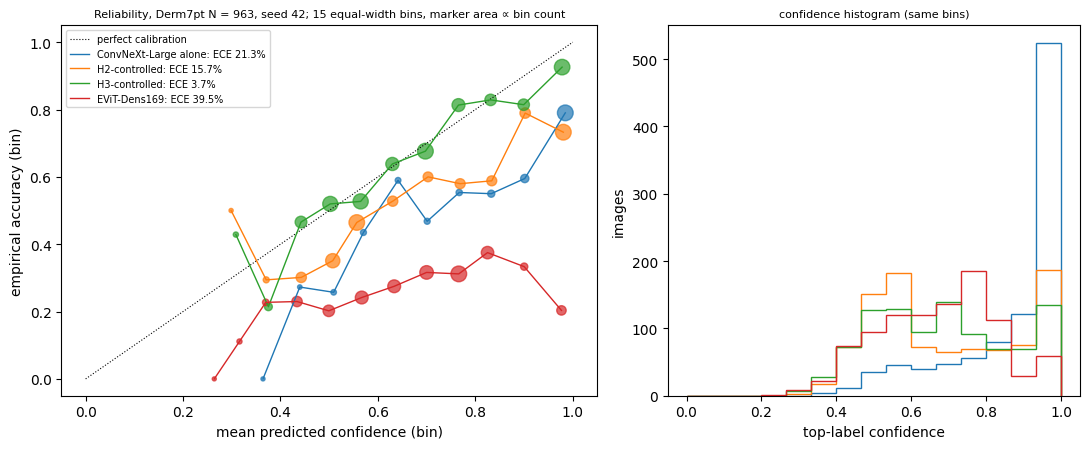

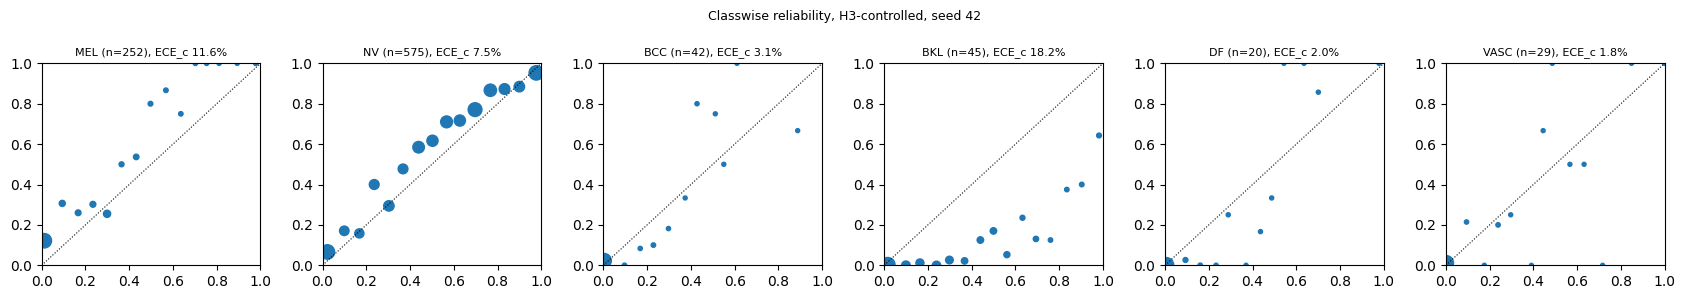

In [12]:
CAL = ["ECE15", "ECE15-mass", "Classwise-ECE", "Brier", "NLL", "Confidence", "Accuracy", "Conf-Acc gap"]
cal = PER_SEED.groupby("Configuration", sort=False)[CAL].agg(["mean", "std"]).loc[NAMES]
CAL_TXT = pd.DataFrame({m: [fmt(cal.at[n, (m, "mean")], cal.at[n, (m, "std")], 3 if m in ("Brier", "NLL") else 2) for n in NAMES]
                        for m in CAL}, index=NAMES)
for m in ["ECE15", "Brier", "NLL"]:
    CAL_TXT[f"{m} 95% CI"] = [CI.at[n, f"{m} [unstratified]"].split(" ", 1)[1] for n in NAMES]
print(CAL_TXT.to_string())
CAL_TXT.to_csv(os.path.join(OUT_DIR, "T_calibration.csv"))
save_tex(CAL_TXT[["ECE15", "ECE15-mass", "Classwise-ECE", "Brier", "NLL", "Conf-Acc gap"]], "T_calibration.tex",
         f"Calibration on Derm7pt (N = {N}), mean $\\pm$ SD over seeds. ECE15: 15 equal-width bins on top-label confidence "
         "(empty bins weight 0); ECE15-mass: 15 equal-mass bins; classwise ECE: one-vs-rest, 15 equal-width bins, averaged over classes; "
         "Brier: multiclass, range [0, 2]; NLL in nats. ECE values and gap in \\%.", "tab:calibration")

def apply_T(P, T):
    z = np.log(np.clip(P, 1e-12, 1)) / T; z -= z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
def fit_T(Pv, yv):
    f = lambda t: -np.log(np.clip(apply_T(Pv, t)[np.arange(len(yv)), yv], 1e-12, 1)).mean()
    return minimize_scalar(f, bounds=(0.05, 20), method="bounded").x
if HAS_VAL:
    rows = []
    for n in [x for x in NAMES if x not in ("EViT-Dens169", "H2-original")]:
        for s in SEEDS:
            T = fit_T(CONF[s][n]["val"], ENS["controlled"][s]["y_val"])
            m0, m1 = metrics(y, CONF[s][n]["test"]), metrics(y, apply_T(CONF[s][n]["test"], T))
            rows.append({"Configuration": n, "Seed": s, "T (fitted on HAM val)": T, "ECE15 before": m0["ECE15"], "ECE15 after": m1["ECE15"],
                         "NLL before": m0["NLL"], "NLL after": m1["NLL"], "Brier before": m0["Brier"], "Brier after": m1["Brier"],
                         "Accuracy (unchanged)": m1["Accuracy"]})
    TS = pd.DataFrame(rows); TS.round(4).to_csv(os.path.join(OUT_DIR, "T_temperature_scaling_supplementary.csv"), index=False)
    print("\nSource-fitted temperature scaling (supplementary):")
    print(TS.groupby("Configuration", sort=False).mean(numeric_only=True).drop(columns="Seed").round(3).to_string())

# reliability diagrams (reporting seed)
rel_names = [n for n in ["ConvNeXt-Large alone", "H2-controlled", "H3-controlled", "EViT-Dens169"] if n in NAMES]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
ax[0].plot([0, 1], [0, 1], "k:", lw=0.8, label="perfect calibration")
for i, n in enumerate(rel_names):
    P = CONF[REPORT_SEED][n]["test"]; conf = P.max(1); corr = (P.argmax(1) == y).astype(float); b = bin_index(conf)
    cnt = np.bincount(b, minlength=N_BINS); acc_b = np.bincount(b, weights=corr, minlength=N_BINS); cf_b = np.bincount(b, weights=conf, minlength=N_BINS)
    nz = cnt > 0
    ax[0].plot(cf_b[nz] / cnt[nz], acc_b[nz] / cnt[nz], "-", c=f"C{i}", lw=1,
               label=f"{n}: ECE {100*ece_equal_width(conf, corr):.1f}%")
    ax[0].scatter(cf_b[nz] / cnt[nz], acc_b[nz] / cnt[nz], s=8 + 120 * cnt[nz] / cnt.max(), c=f"C{i}", alpha=0.7)
    ax[1].hist(conf, bins=np.linspace(0, 1, N_BINS + 1), histtype="step", color=f"C{i}", label=n)
ax[0].set_xlabel("mean predicted confidence (bin)"); ax[0].set_ylabel("empirical accuracy (bin)"); ax[0].legend(fontsize=7)
ax[0].set_title(f"Reliability, Derm7pt N = {N}, seed {REPORT_SEED}; 15 equal-width bins, marker area ∝ bin count", fontsize=8)
ax[1].set_xlabel("top-label confidence"); ax[1].set_ylabel("images"); ax[1].set_title("confidence histogram (same bins)", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"F_reliability_seed{REPORT_SEED}.png"), dpi=300); plt.show()

# classwise reliability for the proposed model (reporting seed)
fig, axs = plt.subplots(1, C, figsize=(17, 3))
P = CONF[REPORT_SEED]["H3-controlled"]["test"]
for k, a in enumerate(axs):
    pk = P[:, k]; ev = (y == k).astype(float); b = bin_index(pk); cnt = np.bincount(b, minlength=N_BINS); nz = cnt > 0
    a.plot([0, 1], [0, 1], "k:", lw=0.8)
    a.scatter((np.bincount(b, weights=pk, minlength=N_BINS)[nz] / cnt[nz]), (np.bincount(b, weights=ev, minlength=N_BINS)[nz] / cnt[nz]),
              s=8 + 100 * cnt[nz] / cnt.max())
    a.set_title(f"{CLASSES[k]} (n={SUPPORT[k]}), ECE_c {100*ece_equal_width(pk, ev):.1f}%", fontsize=8); a.set_xlim(0, 1); a.set_ylim(0, 1)
plt.suptitle(f"Classwise reliability, H3-controlled, seed {REPORT_SEED}", fontsize=9); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, f"F_classwise_reliability_seed{REPORT_SEED}.png"), dpi=300); plt.show()

## 11. The macro-F1 surrogate: corrected equality condition, checked on every run (#6)

Write a_c = P_c and b_c = R_c. Using the identity h(a, b) = 2ab/(a+b) = (a+b)/2 − (a−b)²/(2(a+b)) together with Sedrakyan's form of the Cauchy–Schwarz inequality:

F̃ − F̄ = (1/2C) [ Σ_c (P_c − R_c)²/(P_c + R_c) − (Σ_c (P_c − R_c))² / Σ_c (P_c + R_c) ] ≥ 0,

with the sums over classes where P_c + R_c > 0. Equality holds **iff (P_c − R_c)/(P_c + R_c) is the same for every such class, i.e. iff P_c/R_c is constant**. Identical (P_c, R_c) pairs are only a special case. Because P_c/R_c = n_c/n̂_c (true count over predicted count) whenever TP_c > 0, equality holds iff the prediction-to-truth count ratio is the same for every class with at least one true positive. When every class has TP_c > 0, that ratio must be 1: the predicted class counts must equal the true class counts. The bias therefore grows with the dispersion of n_c/n̂_c, i.e. with how far the predicted class marginal departs from the true one. Heterogeneous per-class performance alone does not create it.

In [13]:
rows = []
for s in SEEDS:
    for n in NAMES:
        P = CONF[s][n]["test"]; cm = fast_cm(y, P.argmax(1)); p, r, f, _ = prf(cm)
        ratio = np.divide(cm.sum(1), cm.sum(0), out=np.full(C, np.nan), where=cm.sum(0) > 0)
        m = metrics(y, P)
        rows.append({"Configuration": n, "Seed": s, "Macro-P": m["Macro-P"], "Macro-R": m["Macro-R"], "Macro-F1 (Eq. 6)": m["Macro-F1"],
                     "Surrogate F~": m["F1-surrogate"], "Bias (pp)": m["Surrogate bias"], "Bias, closed form (pp)": m["Surrogate bias (closed form)"],
                     "CV of n_c/n^_c": float(np.nanstd(ratio) / np.nanmean(ratio))})
SG = pd.DataFrame(rows)
assert np.allclose(SG["Bias (pp)"], SG["Bias, closed form (pp)"], atol=1e-9)
print(SG.round(2).to_string(index=False))
print(f"\nBias range {SG['Bias (pp)'].min():.2f} to {SG['Bias (pp)'].max():.2f} pp; mean {SG['Bias (pp)'].mean():.2f} pp; "
      f"Spearman(bias, CV of count ratio) = {SG[['Bias (pp)','CV of n_c/n^_c']].corr('spearman').iloc[0,1]:.2f}")
SG.round(4).to_csv(os.path.join(OUT_DIR, "T_surrogate.csv"), index=False)
save_tex(SG[["Configuration", "Seed", "Macro-P", "Macro-R", "Macro-F1 (Eq. 6)", "Surrogate F~", "Bias (pp)"]].round(2).set_index("Configuration"),
         "T_surrogate.tex", "Harmonic-mean surrogate versus macro-F1 on every run; the bias equals the closed form of Section IV-J exactly.", "tab:surrogate")

       Configuration  Seed  Macro-P  Macro-R  Macro-F1 (Eq. 6)  Surrogate F~  Bias (pp)  Bias, closed form (pp)  CV of n_c/n^_c
        EViT-Dens169    42    25.70    30.56             19.67         27.92       8.25                    8.25            1.32
   InceptionV3 alone    42    48.66    46.64             38.66         47.63       8.97                    8.97            0.99
   DenseNet121 alone    42    40.05    43.04             36.80         41.49       4.69                    4.69            0.88
ConvNeXt-Large alone    42    56.55    50.17             46.81         53.17       6.36                    6.36            0.73
         H2-original    42    65.18    49.68             53.19         56.39       3.19                    3.19            0.55
       H2-controlled    42    46.69    48.68             43.40         47.66       4.26                    4.26            0.43
    H3 equal weights    42    60.56    57.48             52.49         58.98       6.49                 

## 12. Ensemble diversity between the three streams (Table IX)

In [14]:
rows = []
for s in SEEDS:
    for a, b in itertools.combinations(["InceptionV3 alone", "DenseNet121 alone", "ConvNeXt-Large alone"], 2):
        pa, pb = CONF[s][a]["test"].argmax(1), CONF[s][b]["test"].argmax(1); ca, cb = pa == y, pb == y
        n11, n00, n10, n01 = (ca & cb).sum(), (~ca & ~cb).sum(), (ca & ~cb).sum(), (~ca & cb).sum()
        Q = (n11 * n00 - n10 * n01) / (n11 * n00 + n10 * n01)
        rows.append({"Pair": f"{a.split()[0]} / {b.split()[0]}", "Seed": s, "Disagreement %": 100 * (pa != pb).mean(),
                     "Yule Q": Q, "rho": np.corrcoef(ca, cb)[0, 1], "Double fault %": 100 * n00 / N})
DV = pd.DataFrame(rows)
print(DV.groupby("Pair", sort=False).agg(["mean", "std"]).drop(columns="Seed").round(3).to_string())
DV.round(4).to_csv(os.path.join(OUT_DIR, "T_diversity.csv"), index=False)

                             Disagreement %         Yule Q           rho        Double fault %       
                                       mean     std   mean    std   mean    std           mean    std
Pair                                                                                                 
InceptionV3 / DenseNet121            55.036  12.644  0.514  0.178  0.271  0.129         34.123  5.085
InceptionV3 / ConvNeXt-Large         52.170  10.912  0.496  0.174  0.253  0.112         23.863  1.961
DenseNet121 / ConvNeXt-Large         50.758  12.858  0.562  0.126  0.283  0.094         23.863  2.329


## 13. Error stratification: MEL↔NV and BKL/BCC (#19)

Uses the full N-image confusion matrices and the Derm7pt metadata (diagnosis sub-type, diagnostic difficulty, location, elevation) from notebook 01. **No images are reproduced. Errors are identified by Derm7pt case number and file name only.**

Confusion matrix, H3-controlled, seed 42 (N = 963):
           pred MEL  pred NV  pred BCC  pred BKL  pred DF  pred VASC
true MEL         90       92         3        64        3          0
true NV          13      479         0        71        7          5
true BCC          4       11        14        12        0          1
true BKL          1        6         1        37        0          0
true DF           0        3         0         2       15          0
true VASC         2       11         1         4        1         10


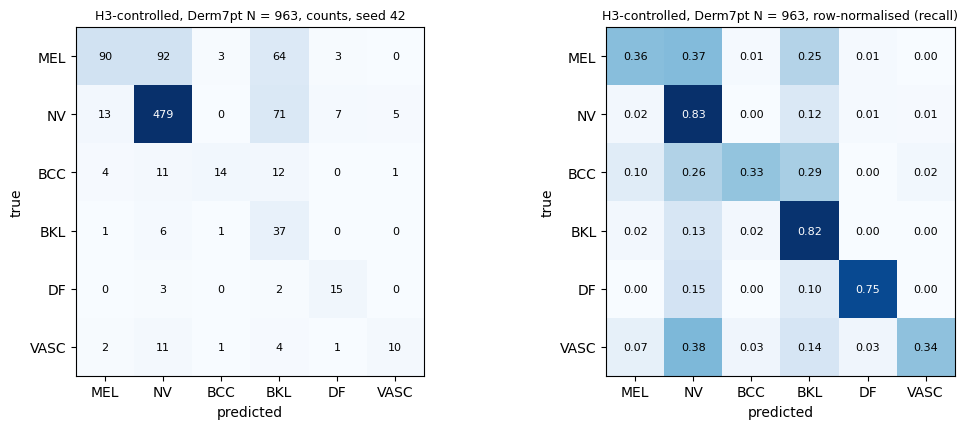


Error families, H3-controlled:
 Seed  MEL->NV  NV->MEL  BCC->NV  BCC->BKL  BKL->NV  BKL->BCC  BKL->MEL  BCC->MEL  MEL->NV share of all errors %
   42       92       13       11        12        6         1         1         4                          28.93
 1000      125       11       18         1       15         2         0         5                          40.72
50000      143       22       17         6       18         0         1         7                          44.69
 2024      120       15       16        12       15         0         0         4                          37.62
31415       94        8        9        12        9         0         0         2                          24.48
MEL -> NV by stratum:
                       Stratum                        Value   n  MEL->NV at seed 42 rate % [Wilson 95%]  MEL->NV at every seed
                     diagnosis                     melanoma   1                   1 100.0 [20.7, 100.0]                      0
              

In [15]:
cm_rep = fast_cm(y, CONF[REPORT_SEED]["H3-controlled"]["test"].argmax(1))
cm_mean = np.mean([fast_cm(y, CONF[s]["H3-controlled"]["test"].argmax(1)) for s in SEEDS], axis=0)
CMD = pd.DataFrame(cm_rep, index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES])
print(f"Confusion matrix, H3-controlled, seed {REPORT_SEED} (N = {N}):"); print(CMD.to_string())
CMD.to_csv(os.path.join(OUT_DIR, f"T_confusion_H3_seed{REPORT_SEED}.csv"))
pd.DataFrame(cm_mean.round(1), index=CMD.index, columns=CMD.columns).to_csv(os.path.join(OUT_DIR, "T_confusion_H3_mean_over_seeds.csv"))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for a, M, t, f in [(ax[0], cm_rep, f"counts, seed {REPORT_SEED}", "d"), (ax[1], cm_rep / cm_rep.sum(1, keepdims=True), "row-normalised (recall)", ".2f")]:
    a.imshow(M, cmap="Blues"); a.set_xticks(range(C)); a.set_xticklabels(CLASSES); a.set_yticks(range(C)); a.set_yticklabels(CLASSES)
    for i in range(C):
        for j in range(C):
            a.text(j, i, format(M[i, j], f), ha="center", va="center", fontsize=8, color="white" if M[i, j] > M.max() / 2 else "black")
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(f"H3-controlled, Derm7pt N = {N}, {t}", fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f"F_confusion_seed{REPORT_SEED}.png"), dpi=300); plt.show()

# summary of the two error families across seeds
fam = []
for s in SEEDS:
    cm = fast_cm(y, CONF[s]["H3-controlled"]["test"].argmax(1)); i = {c: k for k, c in enumerate(CLASSES)}
    fam.append({"Seed": s, "MEL->NV": cm[i["MEL"], i["NV"]], "NV->MEL": cm[i["NV"], i["MEL"]], "BCC->NV": cm[i["BCC"], i["NV"]],
                "BCC->BKL": cm[i["BCC"], i["BKL"]], "BKL->NV": cm[i["BKL"], i["NV"]], "BKL->BCC": cm[i["BKL"], i["BCC"]],
                "BKL->MEL": cm[i["BKL"], i["MEL"]], "BCC->MEL": cm[i["BCC"], i["MEL"]],
                "MEL->NV share of all errors %": 100 * cm[i["MEL"], i["NV"]] / (N - np.trace(cm))})
FAM = pd.DataFrame(fam); print("\nError families, H3-controlled:"); print(FAM.round(2).to_string(index=False))
FAM.to_csv(os.path.join(OUT_DIR, "T_err_families.csv"), index=False)

if COHORT_CSV and os.path.isfile(COHORT_CSV):
    meta = pd.read_csv(COHORT_CSV).sort_values("test_position").reset_index(drop=True)
    assert len(meta) == len(y_full) and (meta["label_index"].values == y_full).all(), "cohort file does not match the test labels"
    meta = meta[KEEP].reset_index(drop=True)
    preds = np.stack([CONF[s]["H3-controlled"]["test"].argmax(1) for s in SEEDS])           # S x N
    pmel = np.stack([CONF[s]["H3-controlled"]["test"][:, 0] for s in SEEDS]).mean(0)
    meta["pred_seed_report"] = preds[SEEDS.index(REPORT_SEED)]
    meta["n_seeds_MEL_to_NV"] = ((preds == 1) & (y == 0)).sum(0)
    meta["n_seeds_wrong"] = (preds != y).sum(0)
    meta["mean_p_MEL"] = pmel
    strata = [c for c in ["diagnosis", "level_of_diagnostic_difficulty", "location", "elevation"] if c in meta.columns]
    def rate_table(true_k, pred_k, label):
        out = []
        sub = meta[y == true_k]
        for col in strata:
            for v, g in sub.groupby(col):
                k = int((g["pred_seed_report"] == pred_k).sum()); n = len(g); lo, hi = wilson(k, n)
                row = {"Stratum": col, "Value": v, "n": n, f"{label} at seed {REPORT_SEED}": k,
                       "rate % [Wilson 95%]": f"{100*k/n:.1f} [{100*lo:.1f}, {100*hi:.1f}]"}
                if label == "MEL->NV":
                    row["MEL->NV at every seed"] = int((g["n_seeds_MEL_to_NV"] == len(SEEDS)).sum())
                out.append(row)
        return pd.DataFrame(out)
    E1 = rate_table(0, 1, "MEL->NV"); E1.to_csv(os.path.join(OUT_DIR, "T_err_MEL_to_NV_by_stratum.csv"), index=False)
    E2 = rate_table(1, 0, "NV->MEL"); E2.to_csv(os.path.join(OUT_DIR, "T_err_NV_to_MEL_by_stratum.csv"), index=False)
    out = []
    for cls in ["BCC", "BKL"]:
        sub = meta[y == CLASSES.index(cls)]
        for col in [c for c in strata if c != "diagnosis"] or [None]:
            groups = sub.groupby(col) if col else [("all", sub)]
            for v, g in groups:
                dist = g["pred_seed_report"].map(dict(enumerate(CLASSES))).value_counts()
                out.append({"True class": cls, "Stratum": col or "all", "Value": v, "n": len(g),
                            **{f"pred {c}": int(dist.get(c, 0)) for c in CLASSES}})
    E3 = pd.DataFrame(out); E3.to_csv(os.path.join(OUT_DIR, "T_err_BCC_BKL_by_stratum.csv"), index=False)
    print("MEL -> NV by stratum:"); print(E1.to_string(index=False))
    print("\nNV -> MEL by stratum:"); print(E2.to_string(index=False))
    print("\nBCC / BKL predictions by stratum:"); print(E3.to_string(index=False))
    idcols = [c for c in ["test_position", "case_num", "derm_file", "diagnosis", "class_ensemble", "level_of_diagnostic_difficulty",
                          "location", "n_seeds_wrong", "n_seeds_MEL_to_NV", "mean_p_MEL"] if c in meta.columns]
    persist = meta[meta["n_seeds_wrong"] == len(SEEDS)][idcols].sort_values(["class_ensemble", "mean_p_MEL"])
    persist.to_csv(os.path.join(OUT_DIR, "persistent_errors.csv"), index=False)
    print(f"\nImages misclassified at every seed: {len(persist)} (IDs in persistent_errors.csv; no images reproduced)")
    print(persist["class_ensemble"].value_counts().to_string())
else:
    print("COHORT_CSV not found -> metadata stratification skipped (confusion-matrix analysis above still applies).")

## 14. Checkpoint sensitivity: final epoch (primary) vs min-validation-loss (#7)

In [16]:
HAS_BV = all(len(ENS["controlled"][s]["test_bestval"]) == 3 for s in ENS["controlled"])
if HAS_BV:
    rows = []
    for s in SEEDS:
        T, Tb = ENS["controlled"][s]["test"], ENS["controlled"][s]["test_bestval"]
        for n, f in [("InceptionV3 alone", lambda d: d["inception"]), ("DenseNet121 alone", lambda d: d["densenet"]),
                     ("ConvNeXt-Large alone", lambda d: d["convnext"]), ("H2-controlled", lambda d: fuse(d, W_H2C)),
                     ("H3-controlled", lambda d: fuse(d, W_H3))]:
            for ck, d in [("final epoch (primary)", T), ("min val loss", Tb)]:
                m = metrics(y, f(d)[KEEP]); rows.append({"Configuration": n, "Checkpoint": ck, "Seed": s, **{k: m[k] for k in ["Accuracy", "Macro-F1", "Macro-AUC", "ECE15"]}})
    for s in SEEDS:
        e = EVIT.get(s)
        if e is not None and "test_last" in e:
            for ck, P in [("best val AUC (reported)", e["test"]), ("final epoch", e["test_last"])]:
                m = metrics(y, P[KEEP]); rows.append({"Configuration": "EViT-Dens169", "Checkpoint": ck, "Seed": s, **{k: m[k] for k in ["Accuracy", "Macro-F1", "Macro-AUC", "ECE15"]}})
    CK = pd.DataFrame(rows)
    CKS = CK.groupby(["Configuration", "Checkpoint"], sort=False)[["Accuracy", "Macro-F1", "Macro-AUC", "ECE15"]].agg(["mean", "std"]).round(2)
    print(CKS.to_string()); CK.round(4).to_csv(os.path.join(OUT_DIR, "T_checkpoint_sensitivity.csv"), index=False)
    ckt = pd.DataFrame({m: [fmt(a, b) for a, b in CKS[m].values] for m in ["Accuracy", "Macro-F1", "Macro-AUC", "ECE15"]},
                       index=[f"{a} | {b}" for a, b in CKS.index])
    save_tex(ckt, "T_checkpoint_sensitivity.tex", "Checkpoint-selection sensitivity (mean $\\pm$ SD over seeds).", "tab:ckpt")
    # epoch of the min-val-loss checkpoint per backbone and seed
    ep = []
    for s in SEEDS:
        man = ENS["controlled"][s]["manifest"].get("per_backbone", {})
        for k, v in man.items():
            ep.append({"Seed": s, "Backbone": k, "best val-loss epoch": v.get("best_val_loss_epoch"), "epochs run": v.get("epochs_run"),
                       "resumes": v.get("resumes"), "peak GPU MB (train)": v.get("peak_gpu_mb_train")})
    if ep:
        EP = pd.DataFrame(ep); print(EP.to_string(index=False)); EP.to_csv(os.path.join(OUT_DIR, "T_best_epochs.csv"), index=False)
else:
    print("Skipped: these runs have no min-val-loss predictions (use the notebook-02 revision runs).")

                                             Accuracy        Macro-F1       Macro-AUC        ECE15       
                                                 mean    std     mean   std      mean   std   mean    std
Configuration        Checkpoint                                                                          
InceptionV3 alone    final epoch (primary)      46.42  10.57    35.35  5.43     78.52  2.48  41.15  10.14
                     min val loss               46.56  11.89    33.53  7.72     78.39  4.90  28.65   9.79
DenseNet121 alone    final epoch (primary)      47.79  13.66    31.89  4.68     76.77  3.97  40.89  11.32
                     min val loss               51.78   9.33    38.58  6.54     79.76  3.25  24.08  10.78
ConvNeXt-Large alone final epoch (primary)      66.36   2.26    46.60  2.68     87.79  0.59  20.72   1.19
                     min val loss               66.25   2.59    46.76  3.25     88.30  0.78  13.86   5.33
H2-controlled        final epoch (primary)    

## 15. Provenance record (#21, #22)

In [17]:
def sha(p):
    h = hashlib.sha256(); h.update(open(p, "rb").read()); return h.hexdigest()[:16]
prov = {"created": datetime.datetime.now().isoformat(timespec="seconds"), "mode": MODE, "seeds": SEEDS, "report_seed": REPORT_SEED,
        "N": int(N), "excluded_test_files": EXCLUDE_TEST_FILES, "bootstrap": {"B": B_BOOT, "rng_seed": BOOT_SEED, "schemes": ["unstratified", "class-stratified"]},
        "weights": {"H3_a_priori": W_H3, "H2_controlled": W_H2C, "H2_original": W_H2O, "equal": W_EQ, "validation_selected": SELECTED_W},
        "calibration_bins": N_BINS, "prior_counts": POOL_COUNTS, "python": platform.python_version(), "numpy": np.__version__,
        "inputs": {f"{arm}/seed{s}/{k}": {"path": p, "sha256_16": sha(p)} for arm in ENS for s in ENS[arm] for k, p in ENS[arm][s]["files"].items()}}
prov["inputs"].update({f"evit/seed{s}/{k}": {"path": p, "sha256_16": sha(p)} for s, e in EVIT.items() if e for k, p in e["files"].items()})
json.dump(prov, open(os.path.join(OUT_DIR, "provenance.json"), "w"), indent=2, default=str)
print("All outputs written to", OUT_DIR); print(sorted(os.listdir(OUT_DIR)))

All outputs written to /content/drive/MyDrive/skin_ablation_v2/analysis_revision
['F_classwise_reliability_seed42.png', 'F_confusion_seed42.png', 'F_mel_roc_seed42.png', 'F_paired_forest.png', 'F_reliability_seed42.png', 'T_best_epochs.csv', 'T_between_seed_deltas.csv', 'T_bootstrap_ci.csv', 'T_bootstrap_ci.tex', 'T_calibration.csv', 'T_calibration.tex', 'T_checkpoint_sensitivity.csv', 'T_checkpoint_sensitivity.tex', 'T_confusion_H3_mean_over_seeds.csv', 'T_confusion_H3_seed42.csv', 'T_diversity.csv', 'T_err_BCC_BKL_by_stratum.csv', 'T_err_MEL_to_NV_by_stratum.csv', 'T_err_NV_to_MEL_by_stratum.csv', 'T_err_families.csv', 'T_fusion_weights.csv', 'T_fusion_weights.tex', 'T_headline_mean_sd.csv', 'T_headline_mean_sd.tex', 'T_headline_mean_sd_min_max.csv', 'T_mel_operating_points.csv', 'T_mel_operating_points.tex', 'T_mel_reconciliation.csv', 'T_paired_tests.csv', 'T_paired_tests.tex', 'T_per_class_ConvNeXtLarge_alone_all_seeds.csv', 'T_per_class_ConvNeXtLarge_alone_mean_sd.csv', 'T_per_cl